# Libraries

To run this you need the libraries below. You just need to install the with `pip`. If you want to know more about `andi_datasets`, visit this [link](https://andichallenge.github.io/andi_datasets/).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from andi_datasets.analysis import dataset_angles, get_angle

In [7]:
from andi_datasets.analysis import msd_analysis
mda = msd_analysis()

In [5]:
def get_trajs(df, max_t = None):
    trajs = []
    for _, group in df.groupby('Track ID', sort=False):
        x = group.X.values.astype(float)
        x -= x[0]
        y = group.Y.values.astype(float)
        y -= y[0]
        trajs.append(np.vstack((x[:max_t],y[:max_t])))
        
    return trajs

# Angles

First load trajectories + create BM trajectoies as control for testing

In [8]:
dataframe = pd.read_csv(f'Control Flat maximaA1R1_spots.csv',  header = 2)[1:].sort_values(['Track ID', 'Frame'])

trajs = np.array(get_trajs(dataframe, max_t = 10)).transpose(0,2,1)
Ds = mda.get_diff_coeff(trajs)

Ds.shape

(166,)

In [9]:
i = 1
flat = pd.read_csv(f'Control Flat maximaA1R{i}_spots.csv', 
                   header = 2)[1:].sort_values(['Track ID', 'Frame'])
ridge = pd.read_csv('Control Ridges maximaB1R2rotated_spots.csv', 
                    header = 2)[1:].sort_values(['Track ID', 'Frame'])

trajs_f = get_trajs(flat)
trajs_r = get_trajs(ridge)

# BM trajectories
control = np.random.randn(1000, 2, 20).cumsum(-1)

Calculate angles

In [10]:
angles_f = dataset_angles(trajs_f)
angles_r = dataset_angles(trajs_r)
angles_c = dataset_angles(control)

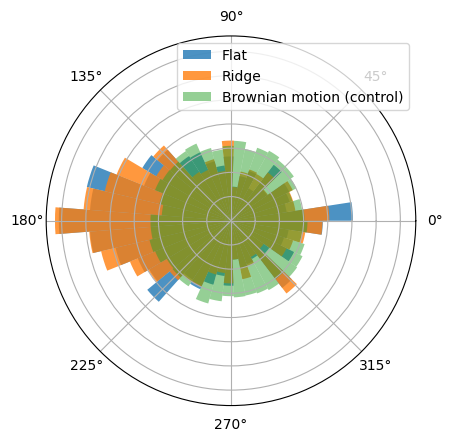

In [11]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
for i, (ang, lab) in enumerate(zip([angles_f, angles_r, angles_c], 
                                    ['Flat', 'Ridge', 'Brownian motion (control)'])):
        ax.hist(2*np.pi*np.array(ang)/360, bins=41, density=1, 
                alpha = .5 if len(lab) > 10 else 0.8,
                label = lab)
ax.legend()
    
plt.setp(ax, yticklabels=[]);

fig.savefig('plot_angles.svg')

# MSD

We perform now the extraction of diffusion coefficient from the MSD

## 2D diffusion

In [12]:
trajs_f = np.array(get_trajs(flat, max_t = 10)).transpose(0,2,1)
trajs_r = np.array(get_trajs(ridge, max_t = 10)).transpose(0,2,1)

In [13]:
D_f = mda.get_diff_coeff(trajs_f)
D_r = mda.get_diff_coeff(trajs_r)

Let's take a look at the mean D for each experiment:

In [14]:
D_f.mean(), D_r.mean()

(29.390705058329008, 23.231540285115283)

And plot their distributions:

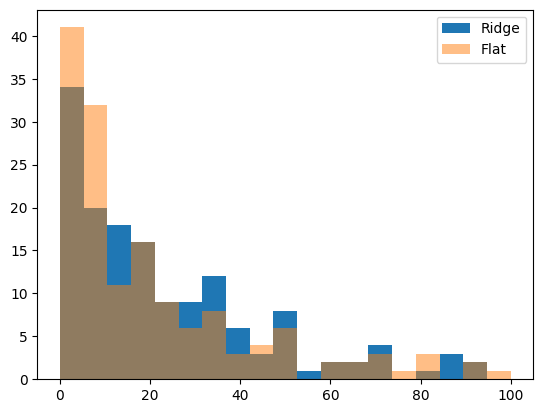

In [40]:
plt.hist(D_f, bins = np.linspace(0,100,20), label = 'Ridge')
plt.hist(D_r, alpha = 0.5, bins = np.linspace(0,100,20), label = 'Flat')

plt.legend();

## Separated by dimension
We now do the same as above but we separate the two dimensions.

In [16]:
trajs_f = np.array(get_trajs(flat, max_t = 10)).transpose(0,2,1)
trajs_r = np.array(get_trajs(ridge, max_t = 10)).transpose(0,2,1)

In [17]:
trajs_f.shape

(166, 10, 2)

So the the spatial dimensions are in the last dimension of the previous tensor, hence X is in the `[:,:,0]`, and Y in `[:,:,1]`. Below we do this but with `[:1]` and `[1:]` (same as before), but allowing us to keep the dimensions consistent.

In [60]:
D_f = mda.get_diff_coeff(trajs_f)
D_r = mda.get_diff_coeff(trajs_r)

D_fx = msd_analysis().get_diff_coeff(trajs_f[:,:,:1])
D_fy = msd_analysis().get_diff_coeff(trajs_f[:,:,1:])

D_rx = msd_analysis().get_diff_coeff(trajs_r[:,:,:1])
D_ry = msd_analysis().get_diff_coeff(trajs_r[:,:,1:])

# D_fx = D_fx[D_fx > 0]
# D_fy = D_fy[D_fy > 0]
# D_rx = D_rx[D_rx > 0]
# D_ry = D_ry[D_ry > 0]

In [19]:
D_fx.mean(), D_fy.mean()

(30.809504275287146, 33.35899289366851)

In [20]:
D_rx.mean(), D_ry.mean()

(37.57958949852932, 14.000108866971155)

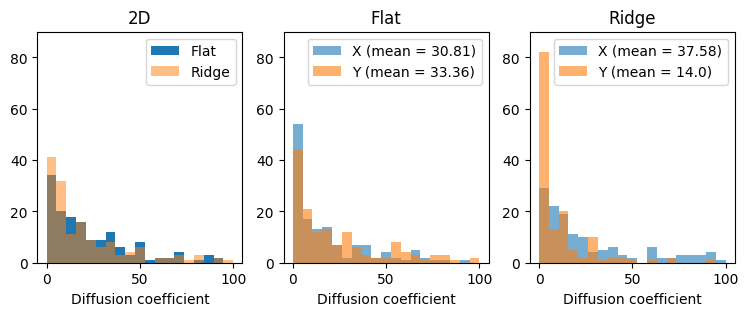

In [21]:
fig, ax = plt.subplots(1, 3, figsize = (9,3))

ax[0].hist(D_f, bins = np.linspace(0,100,20), label = 'Flat')
ax[0].hist(D_r, alpha = 0.5, bins = np.linspace(0,100,20), label = 'Ridge')
ax[0].legend()
ax[0].set_title('2D')

ax[1].hist(D_fx, alpha = 0.6, bins = np.linspace(0,100,20), 
           label = f'X (mean = {np.round(D_fx.mean(),2)})')
ax[1].hist(D_fy, alpha = 0.6, bins = np.linspace(0,100,20),
           label = f'Y (mean = {np.round(D_fy.mean(),2)})')
ax[1].legend()
ax[1].set_title('Flat')

ax[2].hist(D_rx, alpha = 0.6, bins = np.linspace(0,100,20), 
           label = f'X (mean = {np.round(D_rx.mean(),2)})')
ax[2].hist(D_ry, alpha = 0.6, bins = np.linspace(0,100,20),
           label = f'Y (mean = {np.round(D_ry.mean(),2)})')
ax[2].set_title('Ridge')
ax[2].legend()

plt.setp(ax, ylim = (0, 90), xlabel = 'Diffusion coefficient');

In [22]:
D_rx.std()/np.sqrt(D_rx.shape[0])

4.541741238582233

In [23]:
D_fx.std()/np.sqrt(D_fx.shape[0])

3.804759460754666

# Anomalous exponent

In [42]:
trajs_f = np.array(get_trajs(flat, max_t = 10)).transpose(0,2,1)
trajs_r = np.array(get_trajs(ridge, max_t = 10)).transpose(0,2,1)

So the the spatial dimensions are in the last dimension of the previous tensor, hence X is in the `[:,:,0]`, and Y in `[:,:,1]`. Below we do this but with `[:1]` and `[1:]` (same as before), but allowing us to keep the dimensions consistent.

In [44]:
mda.get_exponent??

Signature: mda.get_exponent(trajs: numpy.ndarray, t_lags: list = None)
Source:   
    def get_exponent(self, 
                     trajs:np.ndarray, 
                     t_lags:list = None):
        '''
        Calculates the diffusion coefficient of a trajectory by means of the linear
        fitting of the TA-MSD.
        
        Parameters
        ----------
        traj : np.array
            Set of trajectories of dimenions NxTxD (N: number of trajectories, T: lenght, D: dimension)
        
        t_lags : bool | list
            Time lags used for the TA-MSD.
        
        Returns       
        -------
        np.array
            Diffusion coefficient of the given trajectory.          
        
        '''
        
        # To account for previous versions of this function, we correct if given a single 1D trajectory
        if len(trajs.shape) == 1:
            trajs = trajs[np.newaxis, :, np.newaxis]
        
        if not t_lags:
            N_t_lags = max(4, int(traj

In [55]:
t_lags = np.arange(4,10).tolist()

a_f = mda.get_exponent(trajs_f, t_lags = t_lags)
a_r = mda.get_exponent(trajs_r, t_lags = t_lags)


a_fx = mda.get_exponent(trajs_f[:,:,:1], t_lags = t_lags)
a_fy = mda.get_exponent(trajs_f[:,:,1:], t_lags = t_lags)

a_rx = mda.get_exponent(trajs_r[:,:,:1], t_lags = t_lags)
a_ry = mda.get_exponent(trajs_r[:,:,1:], t_lags = t_lags)

# a_fx = a_fx[a_fx > 0]
# a_fy = a_fy[a_fy > 0]
# a_rx = a_rx[a_rx > 0]
# a_ry = a_ry[a_ry > 0]

/home/gorka/github/andi_datasets/andi_datasets/analysis.py:137: RuntimeWarning: divide by zero encountered in log
  return np.polyfit(np.log(t_lags), np.log(tasmd), deg = 1)[0]


In [56]:
a_fx.mean(), a_fy.mean()

(nan, -0.13517869935996152)

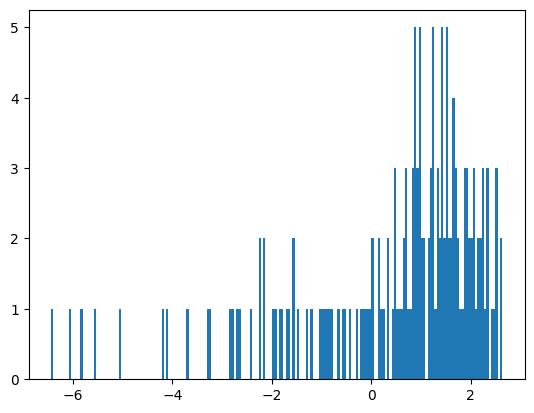

In [59]:
plt.hist(a_fy[a_fy> -10], bins = 200);

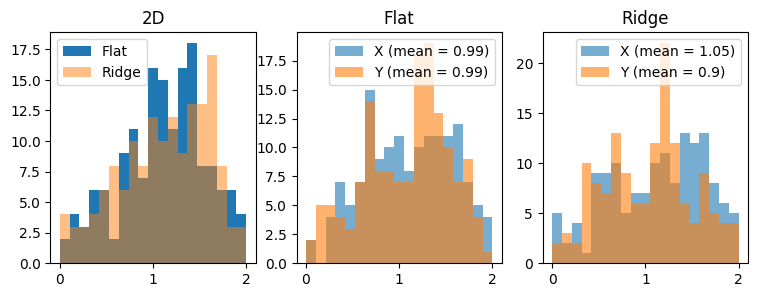

In [26]:
fig, ax = plt.subplots(1, 3, figsize = (9,3))

bins_a = np.linspace(0,2,20)

ax[0].hist(a_f, bins = bins_a, label = 'Flat')
ax[0].hist(a_r, alpha = 0.5, bins = bins_a, label = 'Ridge')
ax[0].legend()
ax[0].set_title('2D')

ax[1].hist(a_fx, alpha = 0.6, bins = bins_a, 
           label = f'X (mean = {np.round(a_fx.mean(),2)})')
ax[1].hist(a_fy, alpha = 0.6, bins = bins_a,
           label = f'Y (mean = {np.round(a_fy.mean(),2)})')
ax[1].legend()
ax[1].set_title('Flat')

ax[2].hist(a_rx, alpha = 0.6, bins = bins_a, 
           label = f'X (mean = {np.round(a_rx.mean(),2)})')
ax[2].hist(a_ry, alpha = 0.6, bins = bins_a,
           label = f'Y (mean = {np.round(a_ry.mean(),2)})')
ax[2].set_title('Ridge')
ax[2].legend()

# plt.setp(ax, ylim = (0, 2), xlabel = 'Anomalous exponent');

# Ensemble TMSD

In [27]:
t_lags = np.arange(1, trajs_f.shape[1])
tmsd_f = mda.tamsd(trajs_f, t_lags = t_lags, dim = 2)
tmsd_r = mda.tamsd(trajs_r, t_lags = t_lags, dim = 2)

In [36]:
t_lags

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [28]:
alpha_f = np.polyfit(np.log(t_lags), np.log(tmsd_f.mean(1)), deg = 1)[0]
alpha_r = np.polyfit(np.log(t_lags), np.log(tmsd_r.mean(1)), deg = 1)[0]

In [29]:
alpha_f, alpha_r

(1.1325132338132993, 1.1576818261097912)

(60.440452253205876, 2000.0)

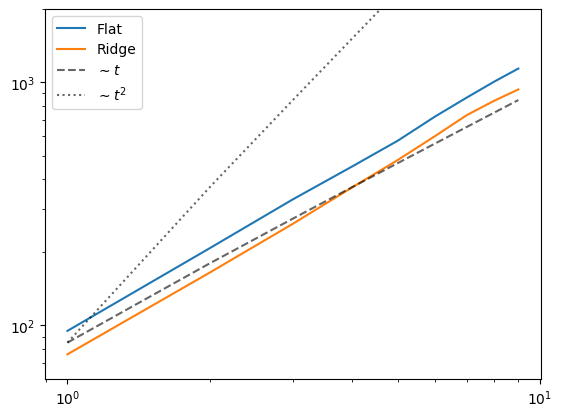

In [30]:
plt.loglog(t_lags, tmsd_f.mean(1), label = 'Flat')
plt.plot(t_lags, tmsd_r.mean(1), label = 'Ridge')

plt.plot(t_lags, t_lags*tmsd_f[0].mean()-10, ls = '--', c = 'k',  label = r'$\sim t$', alpha = 0.6)
plt.plot(t_lags, t_lags**2*tmsd_f[0].mean()-10, ls = ':', c = 'k', label = r'$\sim t^2$', alpha = 0.6)

plt.legend()
plt.ylim(ymax = 2e3)

## Separated by dimensions

In [31]:
tmsd_fx = mda.tamsd(trajs_f[:,:,:1], t_lags = t_lags, dim = 2)
tmsd_fy = mda.tamsd(trajs_f[:,:,1:], t_lags = t_lags, dim = 2)

tmsd_rx = mda.tamsd(trajs_r[:,:,:1], t_lags = t_lags, dim = 2)
tmsd_ry = mda.tamsd(trajs_r[:,:,1:], t_lags = t_lags, dim = 2)

In [32]:
alpha_fx = np.polyfit(np.log(t_lags), np.log(tmsd_fx.mean(1)), deg = 1)[0]
alpha_fy = np.polyfit(np.log(t_lags), np.log(tmsd_fy.mean(1)), deg = 1)[0]

alpha_rx = np.polyfit(np.log(t_lags), np.log(tmsd_rx.mean(1)), deg = 1)[0]
alpha_ry = np.polyfit(np.log(t_lags), np.log(tmsd_ry.mean(1)), deg = 1)[0]


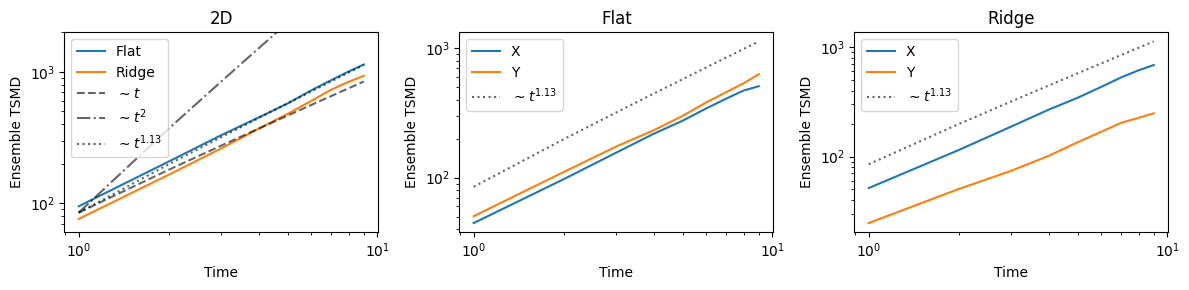

In [33]:
fig, ax = plt.subplots(1, 3, figsize = (12,3), tight_layout = True)



ax[0].loglog(t_lags, tmsd_f.mean(1), label = 'Flat')
ax[0].plot(t_lags, tmsd_r.mean(1), label = 'Ridge')
ax[0].plot(t_lags, t_lags*tmsd_f[0].mean()-10, ls = '--', c = 'k',  label = r'$\sim t$', alpha = 0.6)
ax[0].plot(t_lags, t_lags**2*tmsd_f[0].mean()-10, ls = '-.', c = 'k', label = r'$\sim t^2$', alpha = 0.6)
ax[0].set_title('2D')
ax[0].set_ylim(ymax = 2e3)

ax[1].loglog(t_lags, tmsd_fx.mean(1), label = 'X')
ax[1].plot(t_lags, tmsd_fy.mean(1), label = 'Y')
ax[1].set_title('Flat')

ax[2].loglog(t_lags, tmsd_rx.mean(1), label = 'X')
ax[2].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[2].set_title('Ridge')


for a in ax:
    a.plot(t_lags, t_lags**1.13*tmsd_f[0].mean()-10, ls = ':', c = 'k', label = r'$\sim t^{1.13}$', alpha = 0.6)

ax[0].legend()
ax[1].legend()
ax[2].legend()


plt.setp(ax, xlabel = 'Time', ylabel = 'Ensemble TSMD');

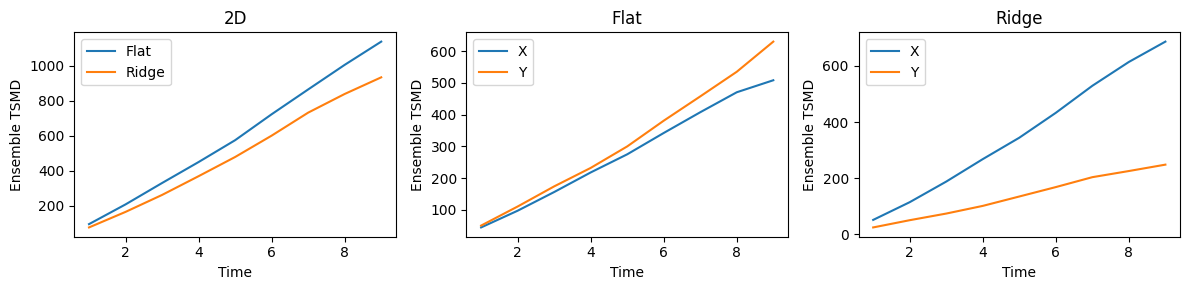

In [34]:
fig, ax = plt.subplots(1, 3, figsize = (12,3), tight_layout = True)



ax[0].plot(t_lags, tmsd_f.mean(1), label = 'Flat')
ax[0].plot(t_lags, tmsd_r.mean(1), label = 'Ridge')
ax[0].set_title('2D')

ax[1].plot(t_lags, tmsd_fx.mean(1), label = 'X')
ax[1].plot(t_lags, tmsd_fy.mean(1), label = 'Y')
ax[1].set_title('Flat')

ax[2].plot(t_lags, tmsd_rx.mean(1), label = 'X')
ax[2].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[2].set_title('Ridge')


# for a in ax:
#     a.plot(t_lags, t_lags**1.13*tmsd_f[0].mean()-10, ls = ':', c = 'k', label = r'$\sim t^{1.13}$', alpha = 0.6)

ax[0].legend()
ax[1].legend()
ax[2].legend()


plt.setp(ax, xlabel = 'Time', ylabel = 'Ensemble TSMD');

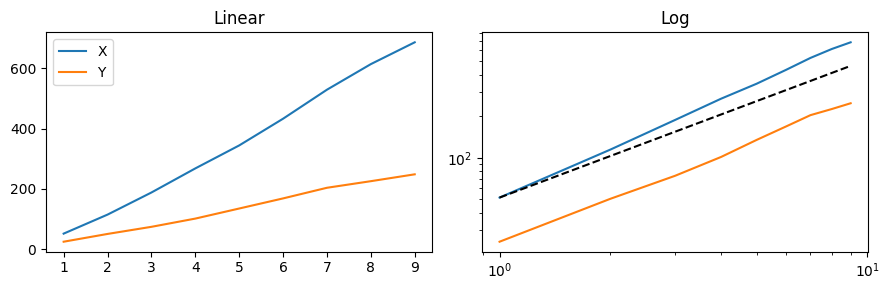

In [39]:
fig, ax = plt.subplots(1, 2, figsize = (9,3), tight_layout = True)


ax[0].plot(t_lags, tmsd_rx.mean(1), label = 'X')
ax[0].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[0].set_title('Linear')
ax[0].legend()

ax[1].loglog(t_lags, tmsd_rx.mean(1), label = 'X')
ax[1].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[1].set_title('Log')

ax[1].plot(t_lags, t_lags*tmsd_rx.mean(1)[0], c = 'k', ls = '--')